Plate scale calc walk-through with HD189340 for VAMPIRES cams post-NBS installation 📷

In [70]:
import numpy as np
import jax.numpy as jnp 

from scipy.signal import fftconvolve
from skimage import feature
from jax import jit, grad, hessian

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm, CenteredNorm

import os
from astropy.io import fits


data_dir = os.getcwd()+'/data/2025_HD189340/coadded/'

Read in relevant headers and take a quick peek.

In [30]:
fits_names = os.listdir(data_dir)
eg_hdul = fits.open(data_dir+fits_names[0])
eg_hdul[0].header
data = eg_hdul[0].data  
fields = ['U_CAMERA', '' ]
bands = ['F610', 'F670', 'F720', 'F760']

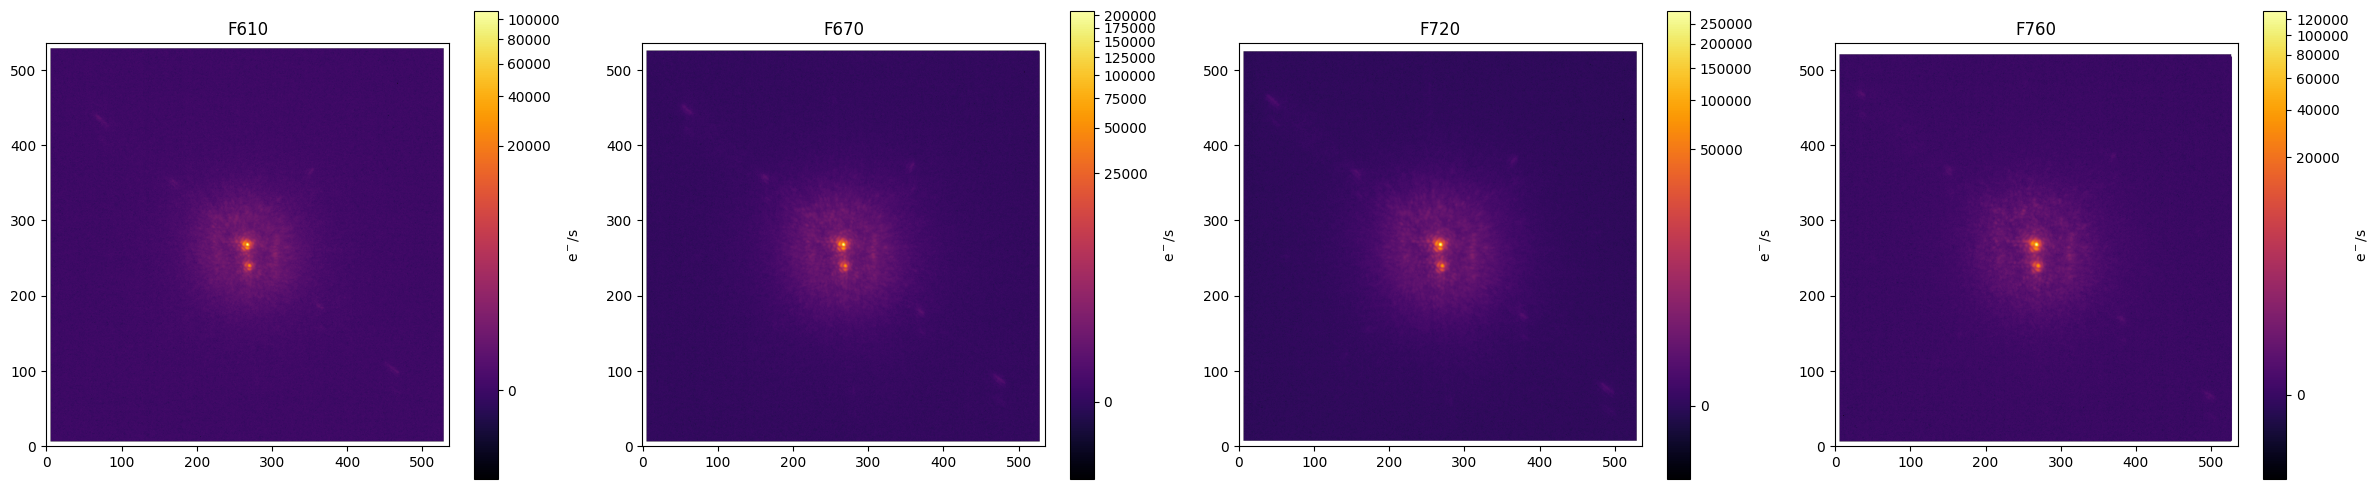

In [37]:
plt.figure(figsize=(24, 5))
%matplotlib inline
for i, img in enumerate(data):
    plt.subplot(1, 4, i+1)
    plt.imshow(img, cmap='inferno', norm=PowerNorm(0.2), origin='lower')
    plt.colorbar(label='e$^-$/s')
    plt.title(bands[i])

plt.tight_layout()

#### 1. Auto-correlation
Smooth and symmetric profiles with sharp peaks at stellar locations - great for fitting loc precisely.

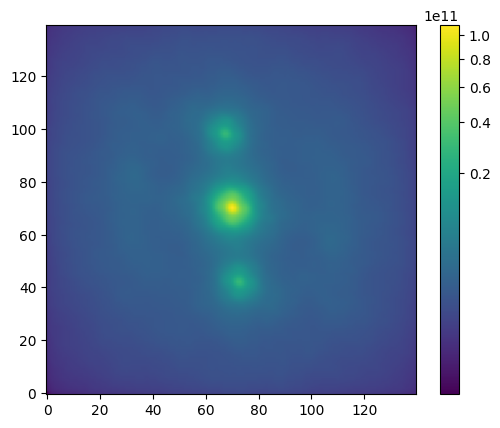

In [57]:
crp_sz = 140
shave_off = (data.shape[1]-crp_sz)//2
t = data[0][shave_off:-shave_off, shave_off:-shave_off]
plt.imshow(fftconvolve(t, t[::-1,::-1], mode='same'), cmap='viridis', norm=PowerNorm(0.3), origin='lower')
plt.colorbar()

In [58]:
def auto_corr(img: np.array, crp_sz: int=None, norm: bool=True) -> np.array:
    if crp_sz is not None:
        shave_off = (img.shape[0]-crp_sz)//2
        img = img[shave_off:-shave_off, shave_off:-shave_off]

    ac = fftconvolve(img, img[::-1, ::-1], mode='same')

    if norm:
        ac /= np.max(ac)

    return ac

#### 2. Find PSF locations
For both primary and companion. 

In [111]:
def gauss2d(px_coords: jnp.array, x0: float, y0: float, sig_x: float, sig_y: float, A: float=1., B: float=0.) -> jnp.array:
    """
        Generates a 2D Gaussian array defined on pixel grid.

        Parameters
        ----------
        px_coords : Array
            Array of shape (2, N, N) describing x,y pixel coordinates respectvely.
        x0, y0 : float
            Center of the Gaussian in units of coordinates
        sig_x, sig_y : float
            Standard deviations of the Gaussian along x and y axes.
        A : float
            Amplitude of the Gaussian.
        B : float
            Z-offset of the Gaussian.
        
        Returns
        -------
        Array
            2D array of shape (N, N) describing Gaussian profile.
    """
    return A * jnp.exp(-((px_coords[0]-x0)**2/(2*sig_x**2) + (px_coords[1]-y0)**2/(2*sig_y**2))) + B

In [130]:
# Qaudratic loss fns great because we can solve with Newton method in single step
def MSE(img1: jnp.array, img2: jnp.array) -> float:
    """
        Computes Mean Squared Error between two images.

        Parameters

        img1, img2 : Array
            2D arrays of the same shape.

        Returns
        -------
        float
            Mean Squared Error between the two images.
    """
    return jnp.mean((img1 - img2)**2)

def loss_fn(p: jnp.array, data: jnp.array, px_coords: jnp.array) -> float:
    """
        Loss function to be minimized.

        Parameters
        ----------
        p : Array
            Array of shape (6,) containing Gaussian parameters:
            [x0, y0, sig_x, sig_y, A, B]
        data : Array
            2D array containing the data image.
        px_coords : Array
            Array of shape (2, N, N) describing x,y pixel coordinates respectvely.

        Returns
        -------
        float
            Computed loss value.
    """
    model = gauss2d(px_coords, p[0], p[1], p[2], p[3], p[4], p[5])
    return MSE(data, model)



In [92]:
def find_binary_peaks(img: np.array, threshold: float=0.5, prox_thresh: int=5):
    """
        Returns location of primary and companion peaks.

        Parameters
        ----------
        img : Array
            2D array representing the image.
        threshold : float
            Threshold value to consider a pixel as a peak.
        prox_thresh : int
            Minimum distance between peaks, pixels.

        Returns
        -------
        (x0, y0), (x1, y1) : 
            x0,y0 location of primary peak (assumed to be brighter star), 
            x1,y1 location of companion peak.
            Returns None if less than two peaks are found.
    """
    peak_coords = feature.peak_local_max(img, threshold_abs=threshold, min_distance=prox_thresh, num_peaks=3) #max number of 3 peaks

    if len(peak_coords) < 2:
        return None
    else:
        max_order = np.argsort([img[tuple(coord)] for coord in peak_coords]) #sort peaks by brightness
        return tuple(peak_coords[max_order[-1]]), tuple(peak_coords[max_order[-2]])

In [ ]:
def crop_about(img, coords, crop_sz):
    """
        Crops a square region about given coordinates.

        Parameters
        ----------
        img : Array
            2D array representing the image.
        coords : (x, y)
            Coordinates about which to crop.
        crop_sz : int
            Size of the cropped square region.

        Returns
        -------
        Array
            Cropped 2D array of shape (crop_sz, crop_sz).
    """
    x, y = coords
    half_sz = crop_sz // 2
    return img[x-half_sz:x+half_sz, y-half_sz:y+half_sz]

In [131]:
grad_fn = jit(grad(loss_fn, argnums=0))
hess_fn = jit(hessian(loss_fn, argnums=0)) # jit and gpu to run v fast

Loop through data

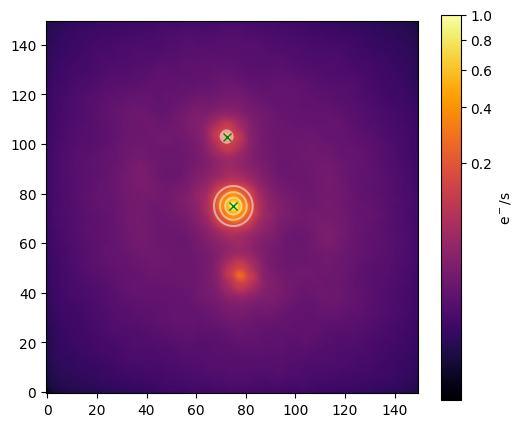

In [186]:
crp_sz, airy_hlf_px = 150, 15 #px, px 
coords= jnp.asarray(jnp.meshgrid(jnp.arange(crp_sz), jnp.arange(crp_sz)), dtype=float) # (2, crp_sz, crp_sz)

plot = True
for fname in os.listdir(data_dir):
    hdul = fits.open(data_dir+fname)

    for i, band_str in enumerate(bands):
        data = hdul[0].data[i]
        ac_img = auto_corr(data, crp_sz=crp_sz, norm=True)
        peak_coords = find_binary_peaks(ac_img, threshold=0.2, prox_thresh=airy_px)

        if peak_coords is not None:
            opt_p = [] # optimised parameter arrays for primary and companion respectively
            for row,col in peak_coords:
                crp_img = ac_img[row-airy_hlf_px:row+airy_hlf_px, col-airy_hlf_px:col+airy_hlf_px]
                crp_coords = coords[:,row-airy_hlf_px:row+airy_hlf_px, col-airy_hlf_px:col+airy_hlf_px]

                p0 = jnp.array([col, row, 2., 2., 1., 0.], dtype=float) # [x0, y0, sig_x, sig_y, A, B]
                p = p0 - jnp.linalg.solve(hess_fn(p0, crp_img, crp_coords), grad_fn(p0, crp_img, crp_coords)) # single-step newton update

                opt_p.append(p)

            if plot:
                plt.figure(figsize=(6,5))
                plt.imshow(ac_img, cmap='inferno', norm=PowerNorm(0.3), origin='lower')
                plt.colorbar(label='e$^-$/s')
                for p in opt_p:
                    x0, y0 = p[0], p[1]
                    plt.contour(gauss2d(coords, x0=x0, y0=y0, sig_x=p[2], sig_y=p[3], A=p[4], B=p[5]), levels=3, colors='w', alpha=0.5)
                    plt.plot(x0, y0, 'gx')


        break

    break